# 113 · Run comparison (src9)
Per-sample hard IoU @ 0.08 (`src9/score.py`) at each run's last saved eval epoch.

Add run names to `RUNS` and every plot updates: per run, one bar plot per box (gastro / plastic / cardboard, one colour each) plus a fourth averaging all boxes (coloured by the run, hatched by its position in `RUNS`), and a final comparison plot of all runs side by side (±1 std whiskers, mean written at the bar's bottom). `train` comes from the run's logged `metrics/train/iou08` (a mean, so no std); epoch is inferred from the saved eval outputs and written in every title as `run@epN`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src9"))
import dataset as D9
import score

RUNS = ["s9-hybrid-vase-1k", "s9-transformer-vase-1k"]   # add more runs here
SPLITS = [("train", None), ("one-object", "id"), ("two-object", "multiple"), ("unseen position", "unseen-position"),
          ("unseen rotation", "rotated"), ("unseen object", "unseen-object"), ("unseen weight", "cylinder"),
          ("unseen speaker", "unseen-speaker"), ("unseen speckles", "unseen-laser"), ("lid", "lid")]
BOXES = ["gastro", "plastic", "cardboard"]
# boxes: one fixed colour each (blue / orange / green); "all boxes": neutral ink
# runs: one colour each for the comparison plots
BOX_COLOR = {"gastro": "#3B6FB6", "plastic": "#E07B39", "cardboard": "#7A9E4E"}
ALL_COLOR = "#4A4A4A"
RUN_COLOR = ["#3B6FB6", "#B04A5A", "#7A5FB0", "#2E8F83", "#C29237", "#555555"]
THR = 0.08
ID_CATS, OOD_CATS = {"id", "multiple"}, {"rotated", "cylinder", "unseen-object", "unseen-speaker", "unseen-laser", "lid"}

/home/ethantu/workspace/good-vibrations/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1061: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


In [2]:
CAT = {(b, s): c for b, cs in D9.CATEGORIES.items() for c, ss in cs.items() for s in ss}
T_IDX = [l for l, _ in SPLITS].index("train")

def last_train_iou08(run):
    vals = [float(l.rsplit(":", 1)[1]) for l in (ROOT / "runs" / run / "logs-rank0.txt").read_text().splitlines() if "metrics/train/iou08" in l]
    return vals[-1]

def stats(df, box=None):
    g = df[df.box == box] if box else df
    m, s = [], []
    for _, cat in SPLITS:
        if cat is None:
            m.append(np.nan); s.append(0.0)
            continue
        h = g[g.category == cat].iou
        m.append(h.mean() if len(h) else np.nan); s.append(h.std() if len(h) else 0.0)
    return np.array(m), np.array(s)

LABEL, STATS, DF = {}, {}, {}
for run in RUNS:
    ep = score.last_epoch(run)
    LABEL[run] = f"{run}@{ep}ep"
    df = score.per_sample(run, ep, THR)
    df["category"] = [CAT.get((b, s)) for b, s in zip(df.box, df.split)]
    DF[run] = df
    per_box = {}
    for box in BOXES + ["all"]:
        m, s = stats(df, box if box != "all" else None)
        m[T_IDX] = last_train_iou08(run)
        per_box[box] = (m, s)
    STATS[run] = per_box
    print(f"{LABEL[run]}: {len(df)} samples")

s9-hybrid-vase-1k@1000ep: 4660 samples


s9-transformer-vase-1k@1000ep: 4660 samples


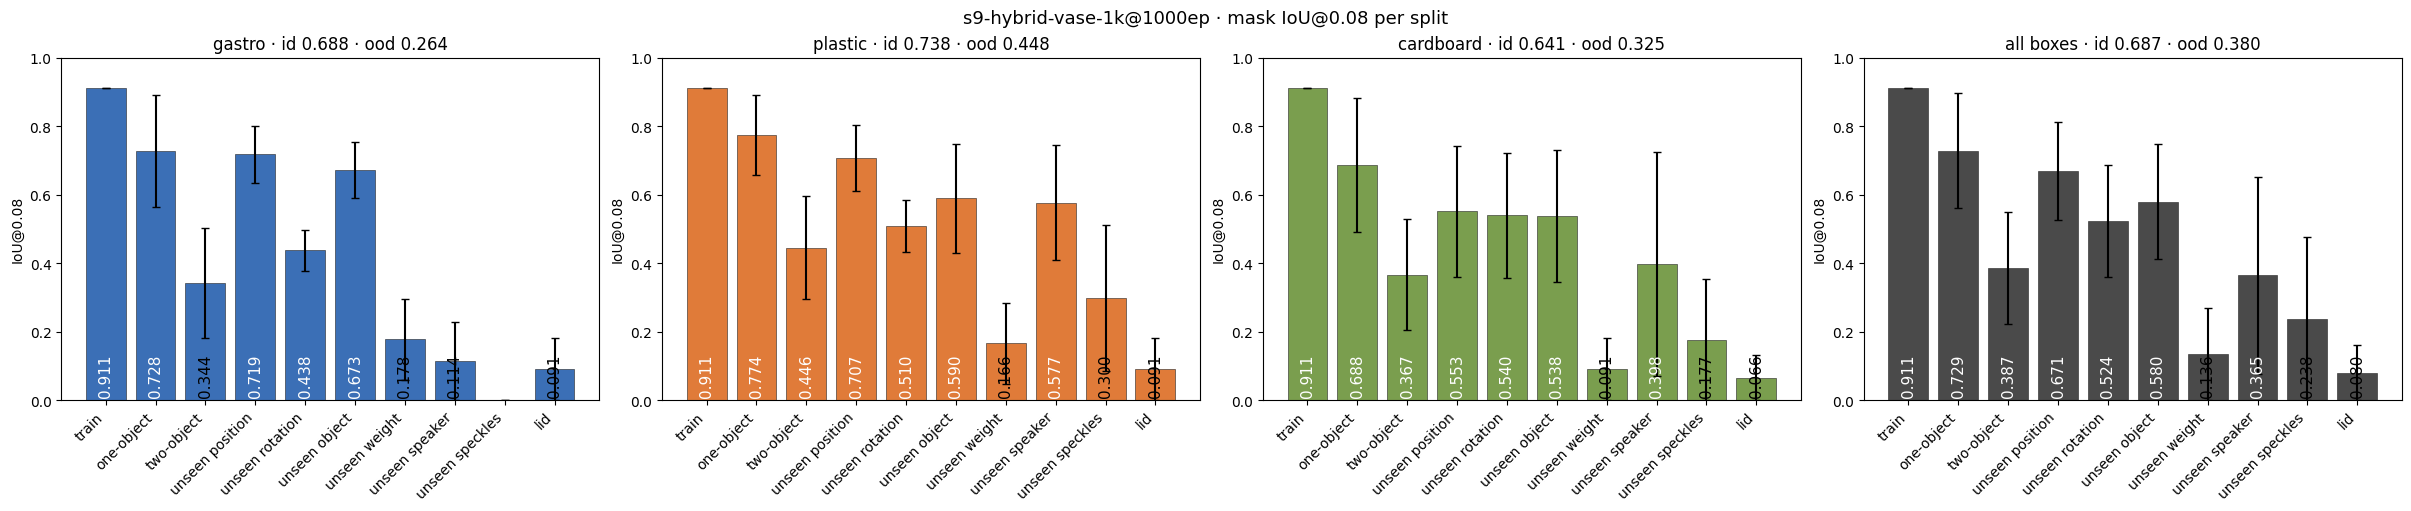

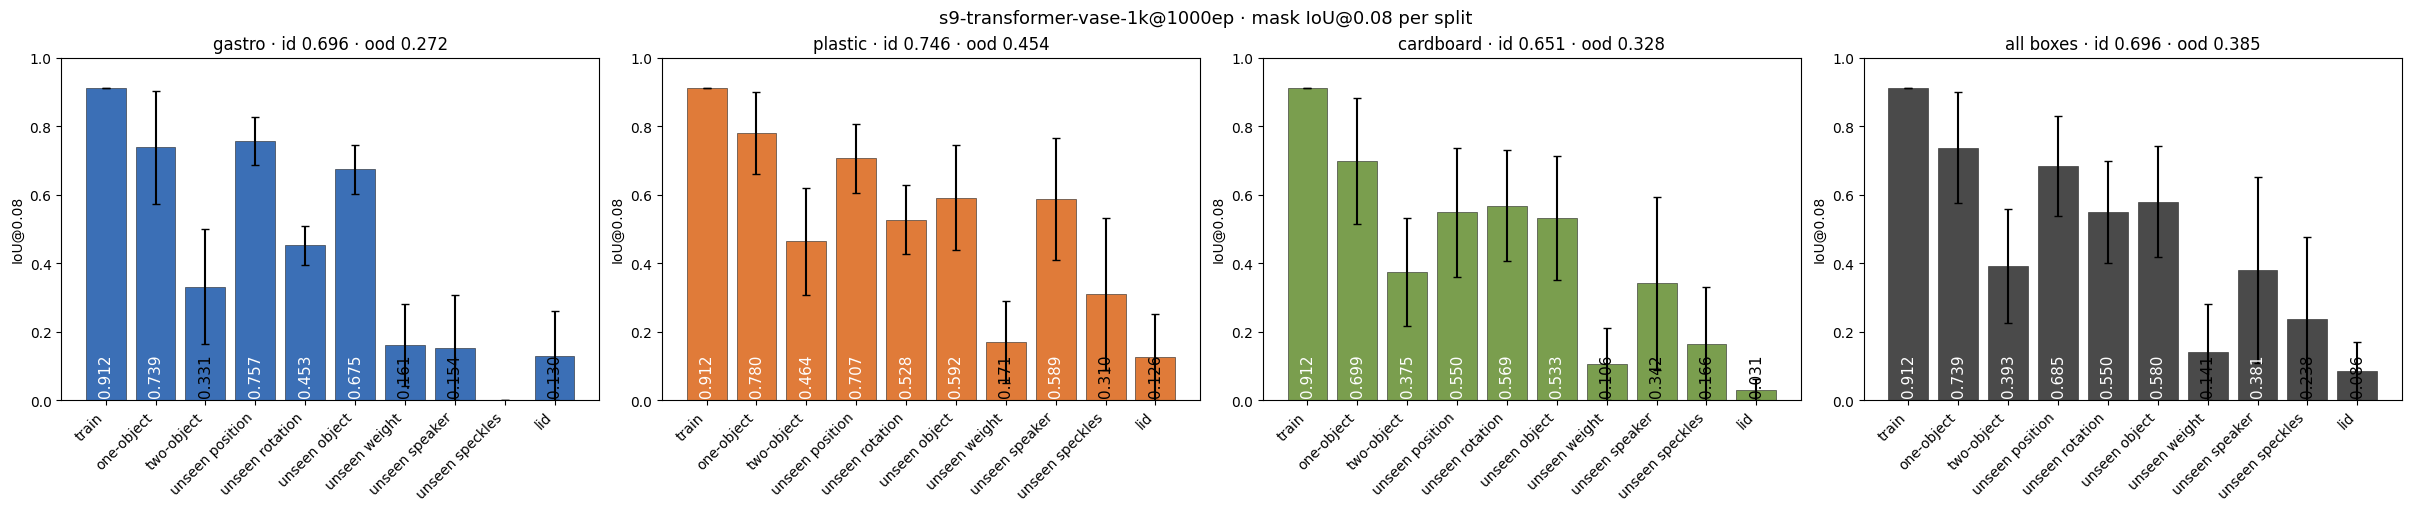

In [3]:
def bars(ax, mean, std, color, title):
    x = np.arange(len(SPLITS))
    ax.bar(x, np.nan_to_num(mean), yerr=np.minimum(std, np.nan_to_num(mean)), color=color, edgecolor="#222222",
           linewidth=0.4, capsize=3)
    for xi, v in zip(x, mean):
        if np.isnan(v): continue
        ax.text(xi, 0.008, f"{v:.3f}", rotation=90, ha="center", va="bottom", fontsize=11,
                color="white" if v > 0.35 else "black")
    ax.set_xticks(x, [s[0] for s in SPLITS], rotation=45, ha="right")
    ax.set_ylim(0, 1); ax.set_ylabel("IoU@0.08"); ax.set_title(title)

def id_ood(df, box=None):
    g = df[df.box == box] if box else df
    return f"id {g[g.category.isin(ID_CATS)].iou.mean():.3f} · ood {g[g.category.isin(OOD_CATS)].iou.mean():.3f}"

for i, run in enumerate(RUNS):
    fig, axes = plt.subplots(1, 4, figsize=(24, 5), constrained_layout=True)
    for ax, box in zip(axes[:3], BOXES):
        m, s = STATS[run][box]
        bars(ax, m, s, BOX_COLOR[box], f"{box} · {id_ood(DF[run], box)}")
    m, s = STATS[run]["all"]
    bars(axes[3], m, s, ALL_COLOR, f"all boxes · {id_ood(DF[run])}")
    fig.suptitle(f"{LABEL[run]} · mask IoU@0.08 per split", fontsize=13)
    plt.show()

### Comparison · all runs, averaged over all boxes
Grouped bars (one colour + hatch per run). Legend also shows each run's mean IoU@0.08 for **id** (one-object + two-object) and **ood** (unseen rotation / weight / object / speaker / speckles + lid).

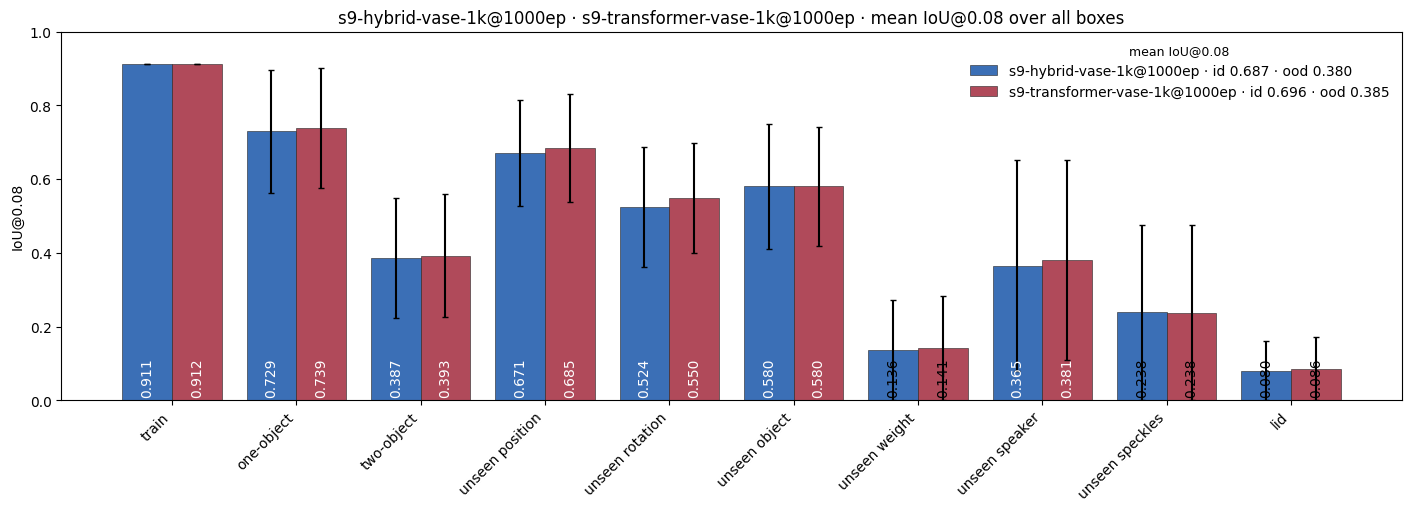

In [4]:
legend = [f"{LABEL[r]} · id {DF[r][DF[r].category.isin(ID_CATS)].iou.mean():.3f}"
          f" · ood {DF[r][DF[r].category.isin(OOD_CATS)].iou.mean():.3f}" for r in RUNS]

x = np.arange(len(SPLITS)); w = 0.8 / len(RUNS)
fig, ax = plt.subplots(figsize=(3 + 1.1 * len(SPLITS), 5), constrained_layout=True)
for i, run in enumerate(RUNS):
    m, s = STATS[run]["all"]
    pos = x + (i - (len(RUNS) - 1) / 2) * w
    ax.bar(pos, np.nan_to_num(m), w, yerr=np.minimum(s, np.nan_to_num(m)),
           color=RUN_COLOR[i % len(RUN_COLOR)], edgecolor="#222222", linewidth=0.4, capsize=2)
    for xi, v in zip(pos, m):
        if np.isnan(v): continue
        ax.text(xi, 0.008, f"{v:.3f}", rotation=90, ha="center", va="bottom", fontsize=10,
                color="white" if v > 0.35 else "black")
ax.set_xticks(x, [s[0] for s in SPLITS], rotation=45, ha="right")
ax.set_ylim(0, 1); ax.set_ylabel("IoU@0.08")
ax.set_title(" · ".join(LABEL[r] for r in RUNS) + " · mean IoU@0.08 over all boxes")
ax.legend(legend, title="mean IoU@0.08", frameon=False, title_fontsize=9, loc="upper right")
plt.show()

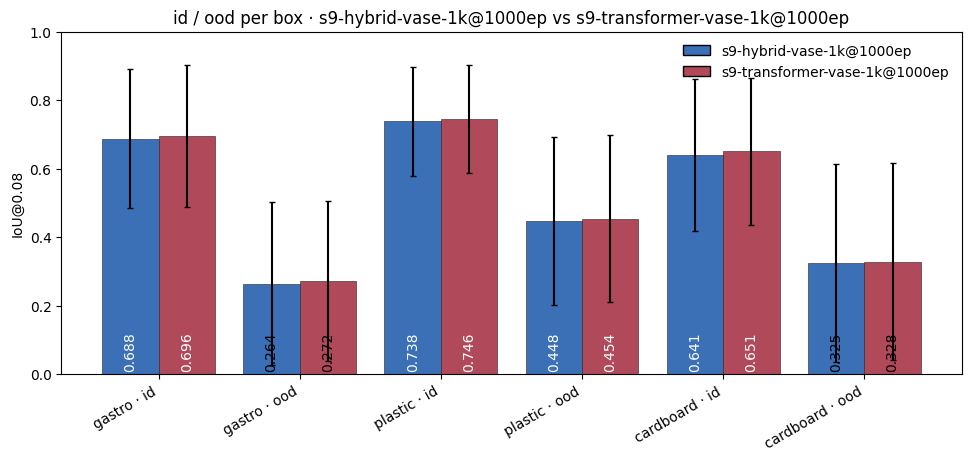

In [5]:
"""per-box id / ood: grouped bars per box, one bar per run (one hue per run)"""
GROUPS = [("id", ID_CATS), ("ood", OOD_CATS)]
x = np.arange(len(BOXES) * len(GROUPS)); w = 0.8 / len(RUNS)
fig, ax = plt.subplots(figsize=(3 + 1.1 * len(BOXES) * len(GROUPS), 4.5), constrained_layout=True)
for i, run in enumerate(RUNS):
    df = DF[run]
    for k, (box, cats) in enumerate([(b, c[1]) for b in BOXES for c in GROUPS]):
        h = df[(df.box == box) & df.category.isin(cats)].iou
        mean, std = h.mean(), h.std()
        xi = (k - (len(GROUPS) - 1) / 2) * w + k * (len(GROUPS) - 1) * w / 2 if False else k
        pos = xi + (i - (len(RUNS) - 1) / 2) * w
        ax.bar(pos, mean, w, yerr=min(std, mean), color=RUN_COLOR[i % len(RUN_COLOR)], edgecolor="#222222",
               linewidth=0.4, capsize=2)
        ax.text(pos, 0.008, f"{mean:.3f}", rotation=90, ha="center", va="bottom", fontsize=10,
                color="white" if mean > 0.35 else "black")
ax.set_xticks([k for k in range(len(BOXES) * len(GROUPS))], [f"{b} · {g}" for b in BOXES for g, _ in GROUPS],
              rotation=30, ha="right")
ax.set_ylim(0, 1); ax.set_ylabel("IoU@0.08")
ax.set_title("id / ood per box · " + " vs ".join(LABEL[r] for r in RUNS))
ax.legend([plt.Rectangle((0, 0), 1, 1, fc=RUN_COLOR[i % len(RUN_COLOR)], ec="black") for i in range(len(RUNS))],
          [LABEL[r] for r in RUNS], frameon=False, loc="upper right")
plt.show()